# 02 · Target analysis: `delay_status` and `actual_delay_hours`

**Questions:** How are the three classes distributed? Is the label consistent with the delay hours? What does the
delay distribution look like (early arrivals, tails)? How does it vary by port, carrier, mode, cargo, priority and route?
Does the problem need imbalance handling?

Labels are **not** changed here. Thresholds: On-Time ≤ 12 h < At-Risk ≤ 48 h < Critical.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as ss

from cargomind_eda import io, stats, plotting as P
from cargomind_eda.config import CLASSES, CLASS_COLORS, THRESHOLDS

P.setup()
s = io.load("shipment_records")
flags = pd.read_csv(ROOT / "data" / "interim" / "shipment_lineage_flags.csv")
s = s.merge(flags[["shipment_id", "outcome_not_observed_in_raw"]], on="shipment_id", how="left", validate="1:1")
s["observed"] = ~s["outcome_not_observed_in_raw"]
print(s.shape, "| outcome not observed in raw:", s.outcome_not_observed_in_raw.sum())

(9850, 18) | outcome not observed in raw: 295


## B1. Label integrity

In [2]:
recomputed = pd.cut(s.actual_delay_hours, [-np.inf, THRESHOLDS["on_time_max"], THRESHOLDS["at_risk_max"], np.inf], labels=CLASSES, right=True)
delay_from_ts = (s.actual_arrival_ts - s.expected_arrival_ts).dt.total_seconds() / 3600
print("label disagrees with thresholds:", (recomputed.astype(str) != s.delay_status.astype(str)).sum())
print("max |delay_hours − (actual − expected)|:", round((delay_from_ts - s.actual_delay_hours).abs().max(), 4), "h")
print("delay_hours resolution:", np.unique(np.round(s.actual_delay_hours * 10 % 1, 6))[:5], "(multiples of 0.1 h)")

label disagrees with thresholds: 0
max |delay_hours − (actual − expected)|: 0.0 h
delay_hours resolution: [0.] (multiples of 0.1 h)


The label is a deterministic function of `actual_delay_hours`, which is itself exactly `actual_arrival_ts − expected_arrival_ts`.
So all three outcome columns encode the same information; any one of them used as a feature would reveal the target.

## B2. Class distribution and imbalance

In [3]:
cnt = s.delay_status.value_counts().reindex(CLASSES)
dist = pd.DataFrame({"n": cnt, "pct": (cnt / cnt.sum() * 100).round(2)})
dist["ci95"] = [tuple(round(v * 100, 1) for v in stats.wilson_ci(k, len(s))) for k in cnt]
obs = s[s.observed].delay_status.value_counts(normalize=True).reindex(CLASSES).mul(100).round(2)
dist["pct_observed_only"] = obs
dist["pct_sea_only"] = s[s.shipping_mode == "sea"].delay_status.value_counts(normalize=True).reindex(CLASSES).mul(100).round(2)
print("imbalance ratio (majority/minority):", round(cnt.max() / cnt.min(), 2))
dist

imbalance ratio (majority/minority): 3.67


,n,pct,ci95,pct_observed_only,pct_sea_only
delay_status,,,,,
On-Time,5422,55.05,"(54.1, 56.0)",55.16,52.63
At-Risk,2951,29.96,"(29.1, 30.9)",29.91,31.57
Critical,1477,14.99,"(14.3, 15.7)",14.92,15.8


delay_status  On-Time  At-Risk  Critical   All
week                                          
2024-12-30        481      287       203   971
2025-01-06       1033      555       156  1744
2025-01-13        977      457       245  1679
2025-01-20        716      512       412  1640
2025-01-27        908      516       294  1718
2025-02-03       1064      504       133  1701
2025-02-10        243      120        34   397
All              5422     2951      1477  9850


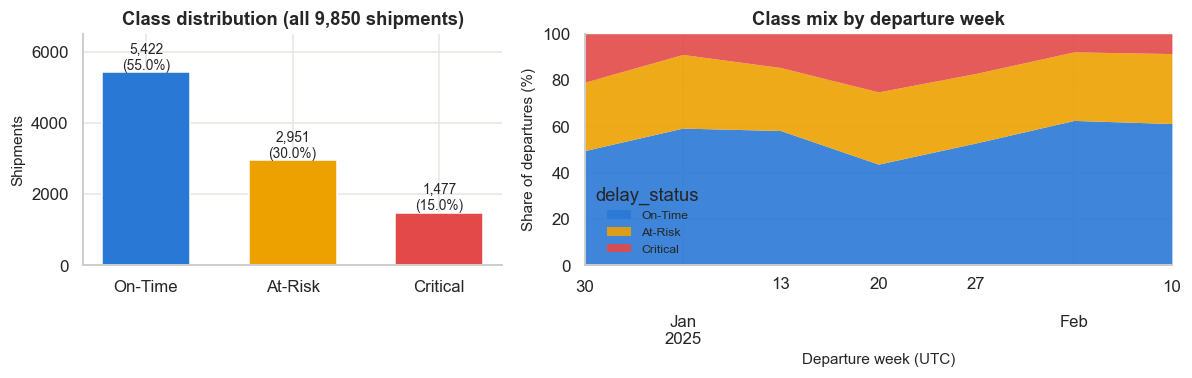

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].bar(CLASSES, cnt.values, color=P.PALETTE, width=0.6)
for i, (n, p) in enumerate(zip(cnt.values, dist.pct.values)):
    ax[0].text(i, n + 80, f"{n:,}\n({p:.1f}%)", ha="center", fontsize=9)
ax[0].set_ylabel("Shipments")
ax[0].set_ylim(0, cnt.max() * 1.2)
ax[0].set_title("Class distribution (all 9,850 shipments)")
wk = s.assign(week=s.departure_ts.dt.tz_localize(None).dt.to_period("W").dt.start_time)
share = pd.crosstab(wk.week, wk.delay_status, normalize="index") * 100
share[CLASSES].plot.area(ax=ax[1], color=P.PALETTE, alpha=0.9, linewidth=0)
ax[1].set_ylabel("Share of departures (%)")
ax[1].set_xlabel("Departure week (UTC)")
ax[1].set_ylim(0, 100)
ax[1].set_title("Class mix by departure week")
ax[1].legend(title="delay_status", loc="lower left", fontsize=8)
P.save(fig, "02_class_distribution")
print(pd.crosstab(wk.week.dt.date, wk.delay_status, margins=True))

## B3. Distribution of `actual_delay_hours`

In [5]:
d = s.actual_delay_hours
summ = d.describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(2)
print(summ.to_string())
print("skewness:", round(ss.skew(d), 2), "| excess kurtosis:", round(ss.kurtosis(d), 2))
print("early arrivals (< 0 h):", (d < 0).sum(), f"({(d < 0).mean()*100:.1f}%)", "| exactly on time (0 h):", (d == 0).sum())

count   9,850
mean    18.35
std     29.45
min     -29.4
1%      -15.3
5%       -9.7
10%        -7
25%      -3.2
50%       8.2
75%      31.7
90%      60.2
95%     79.76
99%     116.1
max       201
skewness: 1.55 | excess kurtosis: 2.54
early arrivals (< 0 h): 3842 (39.0%) | exactly on time (0 h): 25


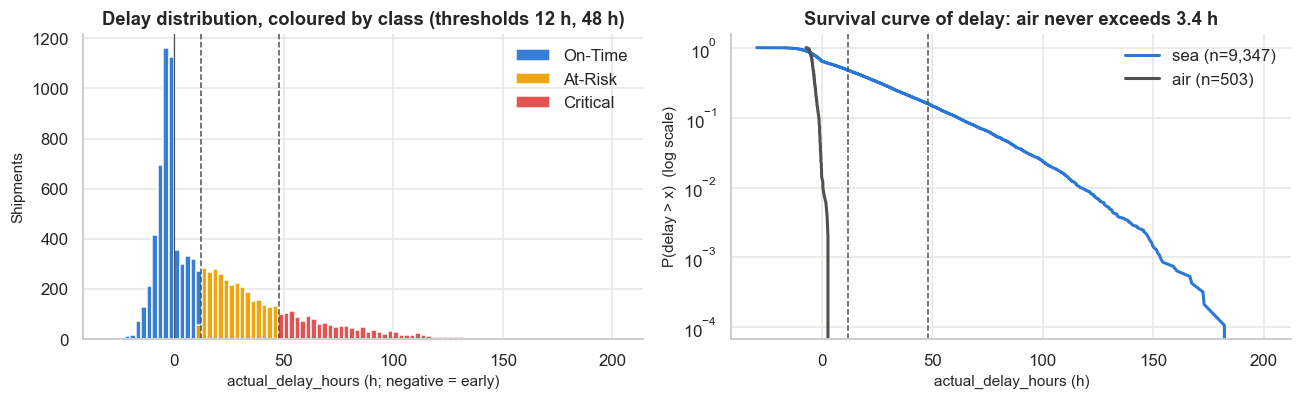

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.arange(-30, 205, 2.5)
for c in CLASSES:
    ax[0].hist(d[s.delay_status == c], bins=bins, color=CLASS_COLORS[c], label=c, alpha=0.95)
for t in THRESHOLDS.values():
    ax[0].axvline(t, color="#52514e", ls="--", lw=1)
ax[0].axvline(0, color="#52514e", lw=0.8)
ax[0].set_xlabel("actual_delay_hours (h; negative = early)")
ax[0].set_ylabel("Shipments")
ax[0].set_title("Delay distribution, coloured by class (thresholds 12 h, 48 h)")
ax[0].legend()
for mode, col in [("sea", "#2a78d6"), ("air", "#52514e")]:
    x = np.sort(d[s.shipping_mode == mode])
    ax[1].plot(x, 1 - np.arange(1, len(x) + 1) / len(x), color=col, label=f"{mode} (n={len(x):,})")
ax[1].set_yscale("log")
ax[1].set_xlabel("actual_delay_hours (h)")
ax[1].set_ylabel("P(delay > x)  (log scale)")
ax[1].set_title("Survival curve of delay: air never exceeds 3.4 h")
for t in THRESHOLDS.values():
    ax[1].axvline(t, color="#52514e", ls="--", lw=1)
ax[1].legend()
P.save(fig, "02_delay_distribution")

### Early arrivals and extreme delays

In [7]:
early = s[d < 0]
print("Early arrivals by mode (% of mode):")
print((s.assign(early=d < 0).groupby("shipping_mode").early.mean() * 100).round(1).to_string())
print("\nEarly-arrival magnitude (h):", early.actual_delay_hours.describe().round(1).to_dict())

q1, q3 = d.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
far = q3 + 3 * (q3 - q1)
print(f"\nTukey fences: 1.5·IQR = {fence:.1f} h → {(d > fence).sum()} shipments; 3·IQR = {far:.1f} h → {(d > far).sum()} shipments")
print("top 10 delays:\n", s.nlargest(10, "actual_delay_hours")[["shipment_id", "origin_port_id", "destination_port_id", "carrier", "departure_ts", "actual_delay_hours"]].to_string(index=False))

Early arrivals by mode (% of mode):
shipping_mode
air   98.4
sea   35.8

Early-arrival magnitude (h): {'count': 3842.0, 'mean': -5.1, 'std': 4.0, 'min': -29.4, '25%': -7.1, '50%': -4.3, '75%': -2.2, 'max': -0.1}

Tukey fences: 1.5·IQR = 84.0 h → 425 shipments; 3·IQR = 136.4 h → 35 shipments
top 10 delays:
 shipment_id origin_port_id destination_port_id             carrier              departure_ts  actual_delay_hours
  SHP004929          NLRTM               LKCMB       Oceanic Lines 2025-01-30 21:00:00+00:00                 201
  SHP004690          NLRTM               CNSHA   Pacific Star Line 2025-01-02 06:00:00+00:00               182.2
  SHP001674          LKCMB               INNSA       Oceanic Lines 2025-02-02 20:00:00+00:00                 173
  SHP004329          CNSHA               MYPKG      Meridian Cargo 2025-01-26 00:00:00+00:00               172.5
  SHP000333          NLRTM               CNSHA       Oceanic Lines 2025-01-02 08:00:00+00:00               167.4
  SHP005595   

In [8]:
# Are the extremes clustered in time/place (suggesting operational events) or scattered (suggesting errors)?
ext = s[d > far]
print("extreme delays by origin:", ext.origin_port_id.value_counts().to_dict())
print("extreme delays by departure date:", ext.departure_ts.dt.date.value_counts().head(8).to_dict())

extreme delays by origin: {'NLRTM': 12, 'CNSHA': 10, 'INNSA': 4, 'USLAX': 4, 'AEJEA': 2, 'MYPKG': 2, 'LKCMB': 1}
extreme delays by departure date: {datetime.date(2025, 1, 2): 9, datetime.date(2025, 2, 2): 5, datetime.date(2025, 1, 18): 5, datetime.date(2025, 1, 25): 4, datetime.date(2025, 1, 26): 3, datetime.date(2025, 1, 28): 2, datetime.date(2025, 1, 30): 2, datetime.date(2025, 1, 21): 2}


Extreme delays (> 3·IQR above Q3) are concentrated at a few origin ports and a few departure dates, which is the pattern
expected from operational disruptions (verified against disruption events in notebook 08), not from random recording
errors. They are timestamp-consistent and **valid extreme observations**; they define the Critical class and must not be
removed or winsorised.

### Threshold proximity (label sensitivity)
How many shipments sit close to a class boundary, where a small timing error would flip the label?

In [9]:
for t in THRESHOLDS.values():
    for w in (1, 2, 4):
        k = ((d - t).abs() <= w).sum()
        print(f"within ±{w} h of {t:.0f} h: {k:4d} ({k/len(d)*100:.1f}%)")

within ±1 h of 12 h:  277 (2.8%)
within ±2 h of 12 h:  512 (5.2%)
within ±4 h of 12 h:  974 (9.9%)
within ±1 h of 48 h:   98 (1.0%)
within ±2 h of 48 h:  205 (2.1%)
within ±4 h of 48 h:  390 (4.0%)


### Filled outcomes vs observed outcomes

In [10]:
comp = s.groupby("observed").actual_delay_hours.describe().round(2)
comp.index = comp.index.map({True: "observed in raw", False: "not observed in raw (filled)"})
display(comp)
ct = pd.crosstab(s.observed, s.delay_status)
print(ct, "\nchi2 p =", round(ss.chi2_contingency(ct)[1], 3), "| KS p =",
      round(ss.ks_2samp(s.loc[s.observed, "actual_delay_hours"], s.loc[~s.observed, "actual_delay_hours"]).pvalue, 3))

,count,mean,std,min,25%,50%,75%,max
observed,,,,,,,,
not observed in raw (filled),295,20.43,31.55,-24.7,-3,10.8,35.35,201
observed in raw,"9,555",18.28,29.39,-29.4,-3.2,8.1,31.6,182.2


delay_status  On-Time  At-Risk  Critical
observed                                
False             151       93        51
True             5271     2858      1426 
chi2 p = 0.343 | KS p = 0.584


The 295 filled outcomes have a distribution indistinguishable from the observed ones. That does not make them observations:
their provenance is unknown. Recommendation: exclude them from training and evaluation, and use them only for sensitivity checks.

## B4. Delay by shipment and network dimensions

For each grouping: class mix, median delay, % delayed (> 12 h) with a 95 % Wilson CI, and Cramér's V vs `delay_status`.
Because **air shipments are always On-Time** (B3), grouping effects are also reported on the sea-only subset to avoid
reading the air/sea mix as a carrier or port effect.

In [11]:
sea = s[s.shipping_mode == "sea"]
dims = ["origin_port_id", "destination_port_id", "carrier", "shipping_mode", "cargo_type", "shipment_priority"]
assoc = pd.concat(
    [stats.screen_categorical(s, dims)[["levels", "cramers_v", "p_value"]].add_suffix("_all"),
     stats.screen_categorical(sea, [c for c in dims if c != "shipping_mode"])[["cramers_v", "p_value"]].add_suffix("_sea")],
    axis=1,
).sort_values("cramers_v_all", ascending=False)
P.save_table(assoc, "02_group_association")
assoc

,levels_all,cramers_v_all,p_value_all,cramers_v_sea,p_value_sea
feature,,,,,
shipping_mode,2,0.2092,9.967e-95,NaN,NaN
origin_port_id,10,0.1552,4.417e-93,0.1621,1.102e-96
carrier,6,0.1089,1.15e-46,0.1153,8.166e-50
shipment_priority,3,0.07867,2.925e-26,0.08236,2.672e-27
destination_port_id,10,0.07441,1.943e-18,0.07917,5.483e-20
cargo_type,3,0.06883,3.69e-20,0.07261,2.833e-21


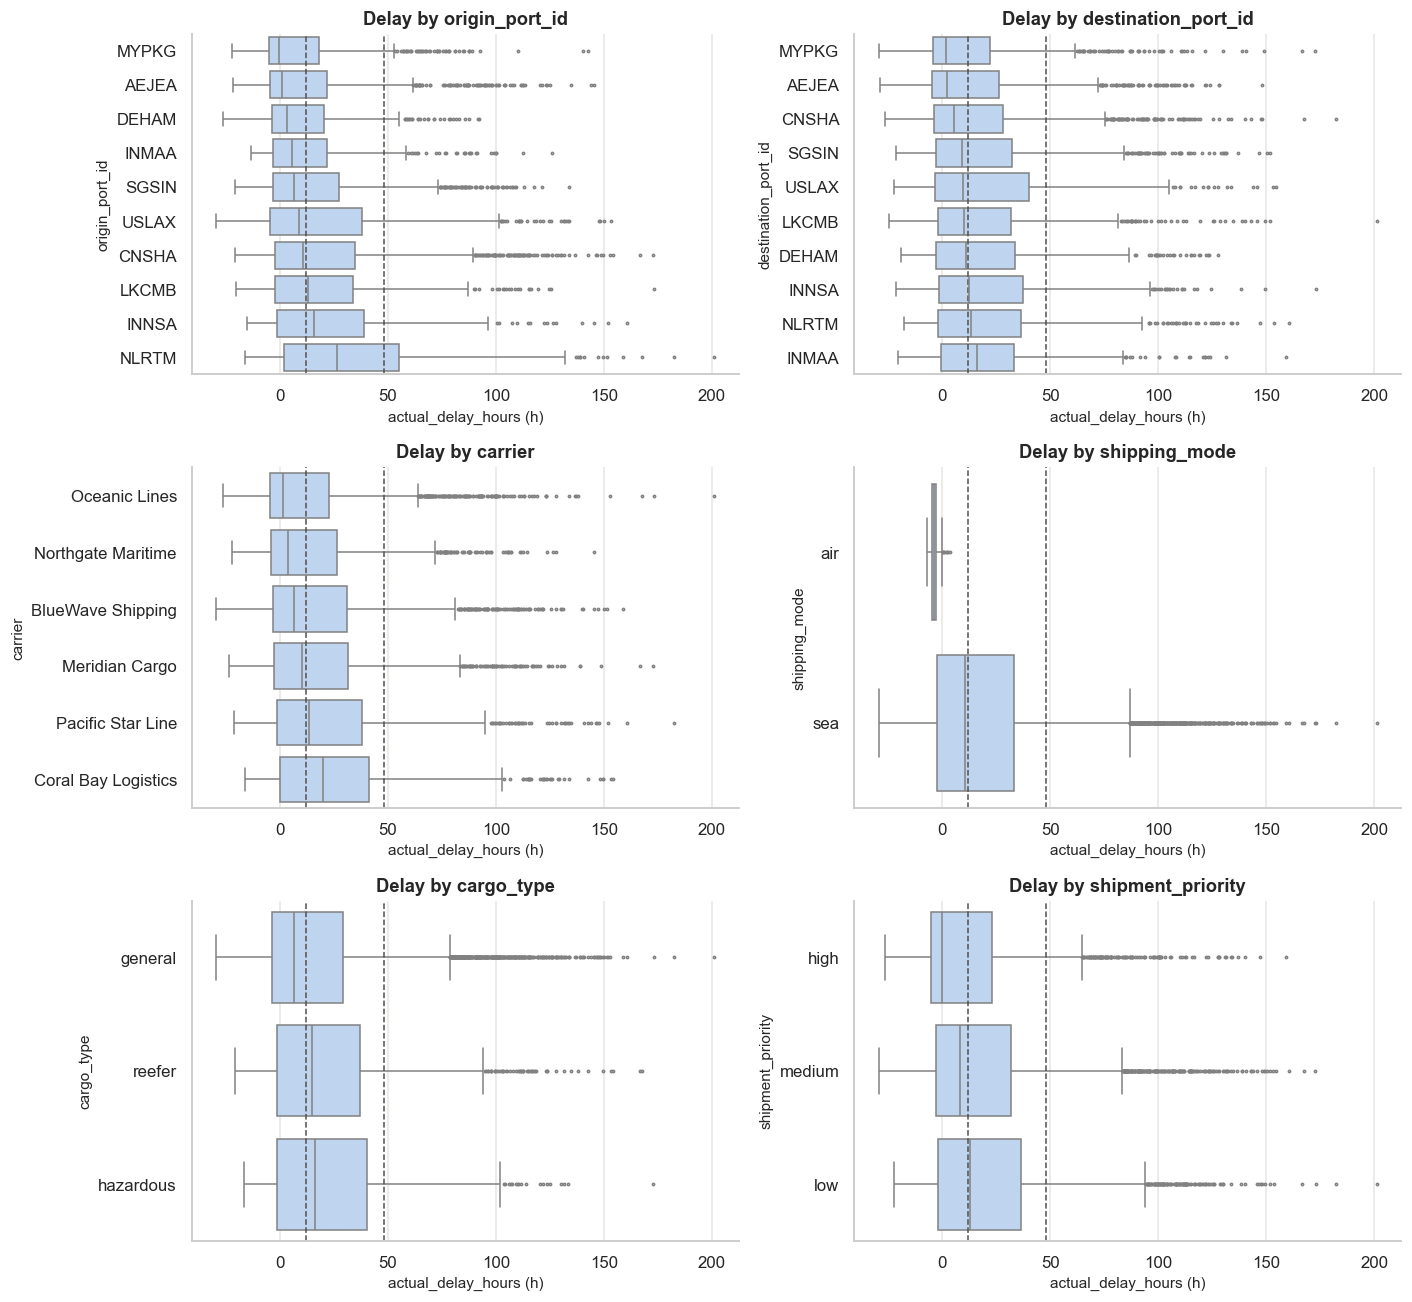

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, c in zip(axes.flat, dims):
    order = s.groupby(c, observed=True).actual_delay_hours.median().sort_values().index
    sns.boxplot(data=s, y=c, x="actual_delay_hours", order=order, ax=ax, color="#b7d3f6", fliersize=1.5, linewidth=1)
    for t in THRESHOLDS.values():
        ax.axvline(t, color="#52514e", ls="--", lw=1)
    ax.set_xlabel("actual_delay_hours (h)")
    ax.set_title(f"Delay by {c}")
P.save(fig, "02_delay_boxplots_by_group")

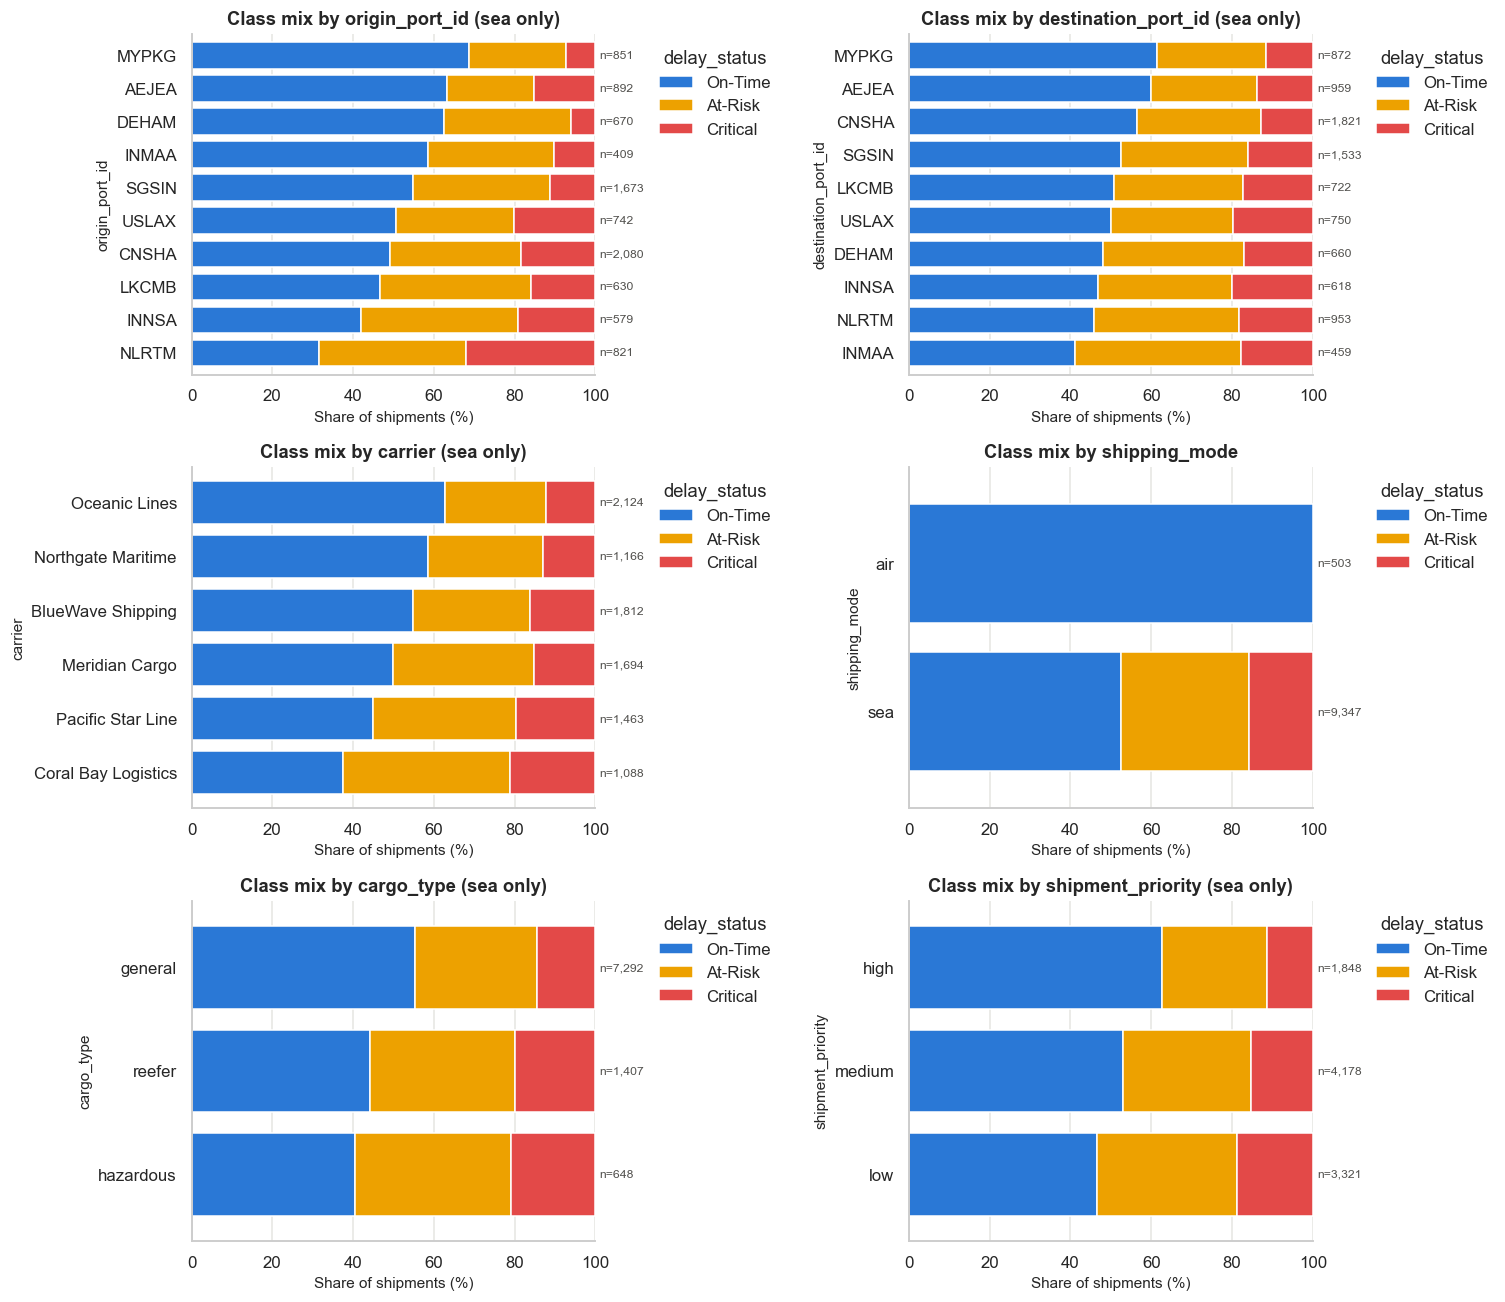

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, c in zip(axes.flat, dims):
    P.stacked_class_bar(sea if c != "shipping_mode" else s, c, ax=ax, title=f"Class mix by {c}" + (" (sea only)" if c != "shipping_mode" else ""))
P.save(fig, "02_class_mix_by_group")

In [14]:
for c in dims:
    print(f"\n── {c} ({'sea only' if c != 'shipping_mode' else 'all'})")
    display(stats.class_rates(sea if c != "shipping_mode" else s, c).sort_values("pct_delayed(>12h)", ascending=False))


── origin_port_id (sea only)


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
origin_port_id,,,,,,,
NLRTM,821,31.7,36.2,32.2,68.3,65.1,71.4
INNSA,579,42,38.9,19.2,58,54,62
LKCMB,630,46.7,37.3,16,53.3,49.4,57.2
CNSHA,2080,49.1,32.4,18.5,50.9,48.7,53
USLAX,742,50.5,29.4,20.1,49.5,45.9,53.1
SGSIN,1673,54.8,34,11.2,45.2,42.8,47.6
INMAA,409,58.4,31.3,10.3,41.6,36.9,46.4
DEHAM,670,62.5,31.3,6.1,37.5,33.9,41.2
AEJEA,892,63.3,21.5,15.1,36.7,33.6,39.9



── destination_port_id (sea only)


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
destination_port_id,,,,,,,
INMAA,459,41.2,41.2,17.6,58.8,54.3,63.2
NLRTM,953,45.9,35.8,18.4,54.1,51,57.3
INNSA,618,46.9,33,20.1,53.1,49.1,57
DEHAM,660,48.2,34.8,17,51.8,48,55.6
USLAX,750,50,30.1,19.9,50,46.4,53.6
LKCMB,722,50.8,32,17.2,49.2,45.5,52.8
SGSIN,1533,52.6,31.5,15.9,47.4,44.9,49.9
CNSHA,1821,56.4,30.8,12.8,43.6,41.3,45.9
AEJEA,959,60,26.2,13.9,40,37,43.2



── carrier (sea only)


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
carrier,,,,,,,
Coral Bay Logistics,1088,37.4,41.5,21,62.6,59.7,65.4
Pacific Star Line,1463,45,35.3,19.7,55,52.5,57.6
Meridian Cargo,1694,49.9,35,15.1,50.1,47.7,52.5
BlueWave Shipping,1812,54.7,29,16.3,45.3,43,47.6
Northgate Maritime,1166,58.6,28.5,13,41.4,38.6,44.3
Oceanic Lines,2124,62.8,25,12.1,37.2,35.2,39.3


... (2 outputs left out)


── cargo_type (sea only)


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
cargo_type,,,,,,,
hazardous,648,40.6,38.4,21,59.4,55.6,63.1
reefer,1407,44.2,36,19.8,55.8,53.2,58.4
general,7292,55.3,30.1,14.6,44.7,43.5,45.8



── shipment_priority (sea only)


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
shipment_priority,,,,,,,
low,3321,46.5,34.7,18.8,53.5,51.8,55.2
medium,4178,53,31.5,15.4,47,45.5,48.5
high,1848,62.7,25.9,11.4,37.3,35.1,39.5


### Route-level delay
Routes have 20–476 sea shipments each (median 72). Ranking routes by raw delay rate over-states extremes for small routes, so routes are
shown with their 95 % CI.

In [15]:
rr = stats.class_rates(sea, "route_id")
rr = rr.join(s.groupby("route_id")[["origin_port_id", "destination_port_id"]].first())
rr["median_delay_h"] = sea.groupby("route_id").actual_delay_hours.median()
print("shipments per route:", rr.n.describe().round(0).to_dict())
P.save_table(rr, "02_route_delay_rates")
top = rr.sort_values("pct_delayed(>12h)", ascending=False)
display(top.head(10))
display(top.tail(10))

shipments per route: {'count': 90.0, 'mean': 104.0, 'std': 82.0, 'min': 20.0, '25%': 51.0, '50%': 72.0, '75%': 136.0, 'max': 476.0}


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high,origin_port_id,destination_port_id,median_delay_h
route_id,,,,,,,,,,
RT0074,42,16.7,50,33.3,83.3,69.4,91.7,LKCMB,INNSA,34
RT0047,46,17.4,30.4,52.2,82.6,69.3,90.9,NLRTM,INNSA,49.8
RT0048,151,21.9,33.8,44.4,78.1,70.9,84,NLRTM,SGSIN,42
RT0053,72,25,43.1,31.9,75,63.9,83.6,NLRTM,LKCMB,29.75
RT0051,73,28.8,30.1,41.1,71.2,60,80.3,NLRTM,USLAX,35.9
RT0014,71,29.6,46.5,23.9,70.4,59,79.8,INNSA,NLRTM,25.3
RT0006,27,29.6,33.3,37,70.4,51.5,84.1,INMAA,USLAX,43.1
RT0019,91,29.7,53.8,16.5,70.3,60.3,78.7,SGSIN,INMAA,23.9
RT0049,210,30,42.4,27.6,70,63.5,75.8,NLRTM,CNSHA,27.6


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high,origin_port_id,destination_port_id,median_delay_h
route_id,,,,,,,,,,
RT0088,77,71.4,20.8,7.8,28.6,19.7,39.5,MYPKG,USLAX,-0.2
RT0044,70,71.4,15.7,12.9,28.6,19.3,40.1,AEJEA,LKCMB,-1
RT0067,143,74.1,22.4,3.5,25.9,19.4,33.6,DEHAM,CNSHA,-0.1
RT0072,52,75,25,0,25,15.2,38.2,DEHAM,MYPKG,-2.35
RT0004,37,75.7,16.2,8.1,24.3,13.4,40.1,INMAA,AEJEA,-0.3
RT0083,58,75.9,17.2,6.9,24.1,15,36.5,MYPKG,INNSA,-1.1
RT0039,182,76.4,13.2,10.4,23.6,18,30.3,AEJEA,SGSIN,-2.25
RT0084,159,78,18.2,3.8,22,16.3,29.1,MYPKG,SGSIN,-2.1
RT0038,60,78.3,11.7,10,21.7,13.1,33.6,AEJEA,INNSA,-2.75


routes whose CI lies entirely above the sea average: 24 | entirely below: 23


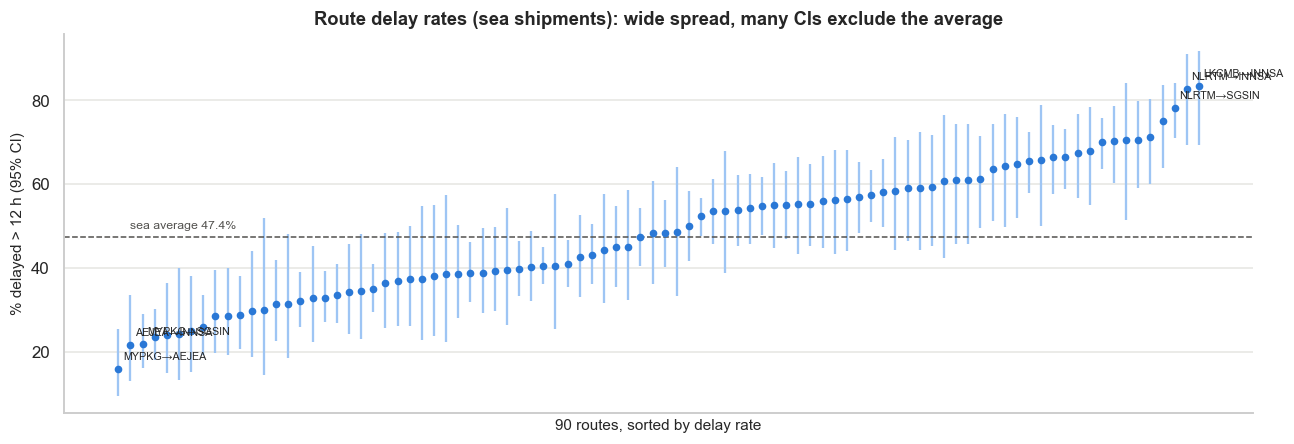

In [16]:
fig, ax = plt.subplots(figsize=(12, 4.2))
r = rr.sort_values("pct_delayed(>12h)").reset_index()
ax.errorbar(range(len(r)), r["pct_delayed(>12h)"], yerr=[r["pct_delayed(>12h)"] - r.ci95_low, r.ci95_high - r["pct_delayed(>12h)"]],
            fmt="o", ms=4, color="#2a78d6", ecolor="#9ec5f4", elinewidth=1.5)
overall = (sea.delay_status != "On-Time").mean() * 100
ax.axhline(overall, color="#52514e", ls="--", lw=1)
ax.text(1, overall + 2, f"sea average {overall:.1f}%", fontsize=8, color="#52514e")
for i in list(range(3)) + list(range(len(r) - 3, len(r))):
    ax.annotate(f"{r.origin_port_id[i]}→{r.destination_port_id[i]}", (i, r['pct_delayed(>12h)'][i]), xytext=(3, 6), textcoords="offset points", fontsize=7)
ax.set_xticks([])
ax.set_xlabel("90 routes, sorted by delay rate")
ax.set_ylabel("% delayed > 12 h (95% CI)")
ax.set_title("Route delay rates (sea shipments): wide spread, many CIs exclude the average")
P.save(fig, "02_route_delay_rates")
print("routes whose CI lies entirely above the sea average:", (rr.ci95_low > overall).sum(), "| entirely below:", (rr.ci95_high < overall).sum())

## B5. Imbalance assessment

* Classes are **moderately imbalanced** — about 55 / 30 / 15 % (majority:minority ≈ 3.7 : 1). This is not extreme; there are
  ~1,480 Critical examples, enough for learning without synthetic oversampling.
* The imbalance is **structured**: the 503 air shipments are all On-Time (max delay 3.4 h), so on the sea subset the mix is
  ~52.6 / 31.6 / 15.8 %. Air shipments add no information about the At-Risk/Critical boundary.
* The class mix drifts by departure week (B2), so any split must be time-based and class weights should be estimated on the
  training window only.
* The problem is **ordinal** (On-Time < At-Risk < Critical, derived from one continuous variable). Errors are not
  symmetric: calling a Critical shipment On-Time is costlier than calling it At-Risk.

Recommended handling for modelling (not applied here): class-weighted loss or balanced sampling within the training window;
evaluation with macro-F1, per-class recall (especially Critical), and an ordinal-aware metric (e.g., quadratic weighted kappa
or a cost matrix); consider modelling `actual_delay_hours` (regression / quantile) and thresholding as a complementary approach,
because it uses the full ordinal information.